# Parihaka DINOv2 U-Net Facies Segmentation

Google Colab / NVIDIA L4 workflow. Select a GPU runtime, then run the cells in order.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = '/content/drive/MyDrive/parihaka_dino_unet'
import os, sys
os.chdir(PROJECT_ROOT)
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
print('PROJECT_ROOT =', PROJECT_ROOT)

Mounted at /content/drive
PROJECT_ROOT = /content/drive/MyDrive/parihaka_dino_unet


In [ ]:
!pip -q install -r requirements_colab.txt

import torch, numpy as np
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.set_float32_matmul_precision('high')
print('torch', torch.__version__)
print('cuda available', torch.cuda.is_available())
if torch.cuda.is_available():
    print('gpu', torch.cuda.get_device_name(0))
    print('bf16 supported', torch.cuda.is_bf16_supported())

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 3.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 7.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 274.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 176.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 181.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.0/274.0 kB 43.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 37.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.4/73.4 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 22.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.5/231.5 kB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
# MLflow is optional: remote tracking is enabled when a DagsHub token is available.
import os
DAGSHUB_USER = 'dragnellstr'
DAGSHUB_REPO = 'sismoML'
os.environ['MLFLOW_TRACKING_URI'] = f'https://dagshub.com/{DAGSHUB_USER}/{DAGSHUB_REPO}.mlflow'
os.environ['MLFLOW_TRACKING_USERNAME'] = DAGSHUB_USER
if not os.environ.get('MLFLOW_TRACKING_PASSWORD'):
    try:
        from google.colab import userdata
        token = userdata.get('DAGSHUB_TOKEN')
        if token:
            os.environ['MLFLOW_TRACKING_PASSWORD'] = token
    except Exception:
        pass
USE_MLFLOW = bool(os.environ.get('MLFLOW_TRACKING_PASSWORD'))
if USE_MLFLOW:
    os.environ['MLFLOW_ENABLE_SYSTEM_METRICS_LOGGING'] = 'true'
print('MLflow enabled:', USE_MLFLOW)


MLflow enabled: False


In [ ]:
from src.config import load_config, ensure_output_dirs, resolve_path

CONFIG_PATH = 'configs/comparison_dinov2_small.yaml'  # DINOv2 + FAPM: inline/crossline train, full inline validation
USER_CONFIG = {
    'project_root': PROJECT_ROOT,
    'data': {
        'train_seismic': 'data/TrainingData_Image.segy',
        'train_labels': 'data/TrainingData_Labels.segy',
        'test1_seismic': 'data/TestData_Image1.segy',
        'test2_seismic': 'data/TestData_Image2.segy',
    },
    'tracking': {'mlflow': {'enabled': USE_MLFLOW}},
    # Matched budget: batch 32 x accumulation 4 = effective batch 128.
    # If the GPU runs out of memory: 'training': {'batch_size': 16, 'gradient_accumulation': 8},
}
cfg = load_config(CONFIG_PATH, USER_CONFIG)
ensure_output_dirs(cfg)
cfg

{'seed': 42,
 'project_root': '/content/drive/MyDrive/parihaka_dino_unet',
 'data': {'train_seismic': 'data/TrainingData_Image.segy',
  'train_labels': 'data/TrainingData_Labels.segy',
  'test1_seismic': 'data/TestData_Image1.segy',
  'test2_seismic': 'data/TestData_Image2.segy',
  'axis_order': 'inline_crossline_depth'},
 'cache': {'dir': 'cache', 'mmap': True},
 'outputs': {'dir': 'outputs/comparison_v2/dinov2_small_fapm',
  'checkpoints': 'outputs/comparison_v2/dinov2_small_fapm/checkpoints',
  'predictions': 'outputs/comparison_v2/dinov2_small_fapm/predictions',
  'logs': 'outputs/comparison_v2/dinov2_small_fapm/logs',
  'figures': 'outputs/comparison_v2/dinov2_small_fapm/figures'},
 'tracking': {'mlflow': {'enabled': False,
   'tracking_uri': 'https://dagshub.com/dragnellstr/sismoML.mlflow',
   'experiment_name': 'parihaka-three-model-comparison-v2',
   'run_name': 'dinov2_small_fapm-comparison-v2',
   'log_system_metrics': True,
   'log_checkpoints': False}},
 'split': {'axis': '

In [ ]:
from src.cache import load_or_create_volume_cache
from src.segy_io import read_segy_volume, validate_label_volume

cache_dir = resolve_path(cfg, cfg['cache']['dir'])
train_seismic, train_meta = load_or_create_volume_cache(resolve_path(cfg, cfg['data']['train_seismic']), cache_dir, 'train_seismic', read_segy_volume, mmap=cfg['cache']['mmap'])
train_labels, label_meta = load_or_create_volume_cache(resolve_path(cfg, cfg['data']['train_labels']), cache_dir, 'train_labels', read_segy_volume, mmap=cfg['cache']['mmap'])
assert train_seismic.shape == train_labels.shape, (train_seismic.shape, train_labels.shape)
validate_label_volume(train_labels)
print('train shape', train_seismic.shape)
print('train read method', train_meta['reader']['read_method'], train_meta['reader'].get('iline_count'), train_meta['reader'].get('xline_count'))
print('label read method', label_meta['reader']['read_method'], label_meta['reader'].get('iline_count'), label_meta['reader'].get('xline_count'))
if train_meta['reader']['read_method'] != 'segyio.tools.cube' or label_meta['reader']['read_method'] != 'segyio.tools.cube':
    raise RuntimeError('Could not read SEG-Y as a geometry cube. Check the cache, data, and headers before training.')
print('label values 1..6 validated in chunks; split-level counts follow below')


train shape (590, 782, 1006)
train read method segyio.tools.cube 590 782
label read method segyio.tools.cube 590 782
label values 1..6 validated in chunks; split-level counts follow below


In [ ]:
from src.transforms import load_or_create_normalization_stats
from src.dataset import load_or_create_split, split_class_summary, range_for_index
from src.comparison_protocol import verify_comparison_split

split = load_or_create_split(train_seismic.shape, cfg['split'], resolve_path(cfg, cfg['split']['path']))
verify_comparison_split(split)
norm_path = resolve_path(cfg, cfg['normalization']['path'])
normalization = load_or_create_normalization_stats(
    train_seismic, split, resolve_path(cfg, cfg['data']['train_seismic']),
    cfg['normalization'], norm_path,
)

class_summary = split_class_summary(train_labels, split)
for subset, stats in class_summary.items():
    print(subset, 'class counts', stats['counts'], 'percent', {k: round(v, 4) for k, v in stats['percent'].items()})
    if stats['missing']:
        raise RuntimeError(f'Missing classes in the {subset} split: {stats["missing"]}')
print('normalization', normalization)
print('split', split)

train class counts {1: 37885694, 2: 118402026, 3: 11660827, 4: 81706208, 5: 2873934, 6: 25960279} percent {1: 13.604, 2: 42.5159, 3: 4.1872, 4: 29.3391, 5: 1.032, 6: 9.3218}
val class counts {1: 14196928, 2: 30111704, 3: 1131547, 4: 21632205, 5: 29107, 6: 6847557} percent {1: 19.1983, 2: 40.7195, 3: 1.5302, 4: 29.2529, 5: 0.0394, 6: 9.2598}
normalization {'lower': -1317.1327465820311, 'upper': 1321.6879956054674, 'mean': 1.3790884080776762, 'std': 379.6490990177582, 'sample_count': 1320480, 'sample_stride': 6, 'provenance': {'version': 2, 'source': '/content/drive/MyDrive/parihaka_dino_unet/data/TrainingData_Image.segy', 'source_size': 1967327920, 'source_mtime_ns': 1748685414000000000, 'shape': [590, 782, 1006], 'split_axis': 'inline', 'train_range': [146, 370], 'train_ranges': [[39, 99], [146, 370], [480, 550]], 'lower_percentile': 0.5, 'upper_percentile': 99.5, 'max_samples': 2000000}}
split {'axis': 'inline', 'axis_index': 0, 'shape': [590, 782, 1006], 'parameters': {'train': [[39,

volume shape [inline, crossline, depth]: (590, 782, 1006)
raw inline section shape [crossline, depth]: (782, 1006)


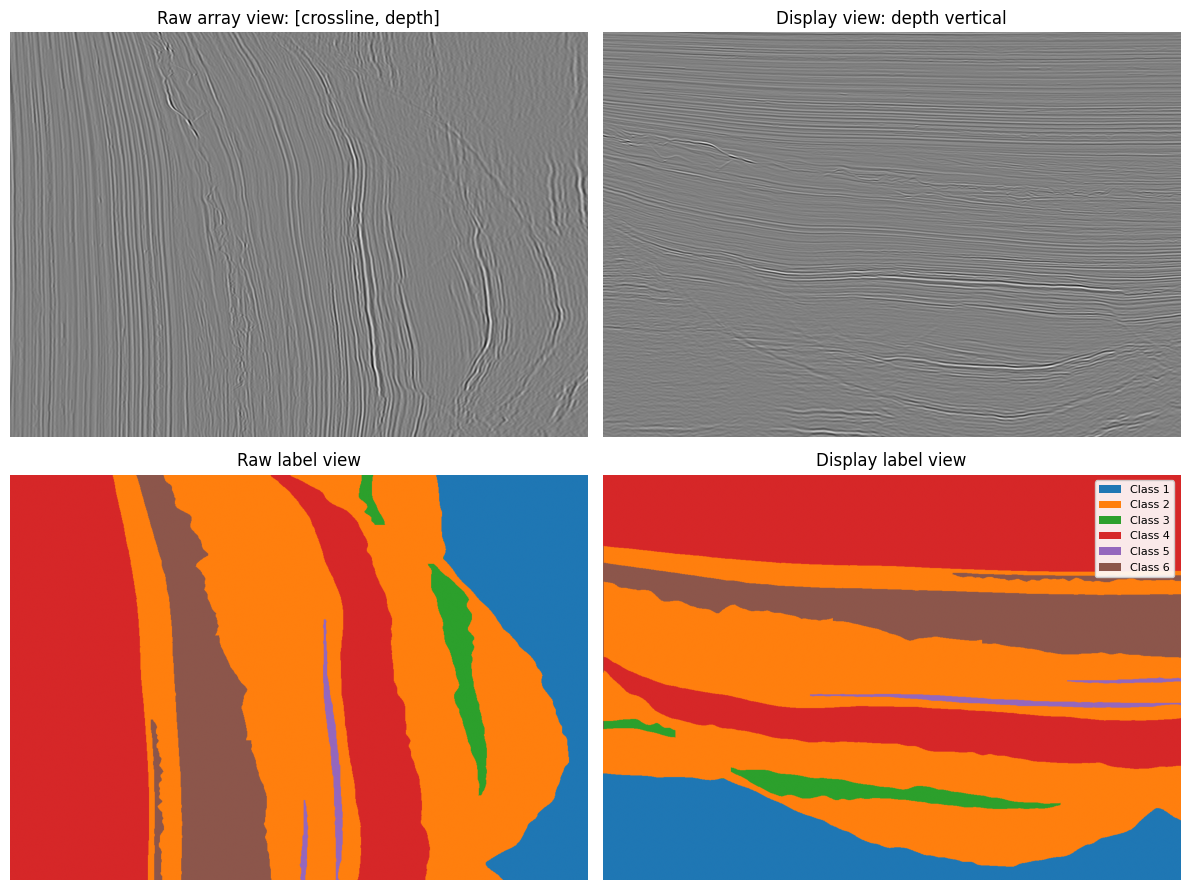

In [ ]:
# Axis QC: the canonical volume order is [inline, crossline, depth].
# Raw inline sections are [crossline, depth]; transpose them to display depth vertically.
from src.visualization import FACIES_CMAP, FACIES_NORM, add_facies_legend, display_section
import matplotlib.pyplot as plt

qc_idx = train_seismic.shape[0] // 2
raw_seis = train_seismic[qc_idx]
raw_lab = train_labels[qc_idx]
print('volume shape [inline, crossline, depth]:', train_seismic.shape)
print('raw inline section shape [crossline, depth]:', raw_seis.shape)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes[0, 0].imshow(raw_seis, cmap='gray', aspect='auto')
axes[0, 0].set_title('Raw array view: [crossline, depth]')
axes[0, 1].imshow(display_section(raw_seis), cmap='gray', aspect='auto')
axes[0, 1].set_title('Display view: depth vertical')
axes[1, 0].imshow(raw_lab, cmap=FACIES_CMAP, norm=FACIES_NORM, aspect='auto')
axes[1, 0].set_title('Raw label view')
axes[1, 1].imshow(display_section(raw_lab), cmap=FACIES_CMAP, norm=FACIES_NORM, aspect='auto')
axes[1, 1].set_title('Display label view')
add_facies_legend(axes[1, 1])
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
from src.dataset import SeismicSliceDataset, FullInlineValidationDataset
from src.comparison_protocol import verify_evaluation_indices

train_ds = SeismicSliceDataset(
    train_seismic, train_labels, split, normalization,
    mode='train', orientations=cfg['dataset']['orientations'],
    patch_size=cfg['dataset']['patch_size'], random_crop=cfg['dataset']['random_crop'],
    feature_mode=cfg['feature_engineering']['mode'], crop_strategy=cfg['dataset'].get('crop_strategy'),
    augmentation=cfg['augmentation'], samples_per_epoch=cfg['dataset']['samples_per_epoch'],
    random_sample_when_limited=cfg['dataset'].get('random_sample_when_limited', True),
    require_all_orientations=cfg['dataset'].get('require_all_orientations', False),
    balance_orientations=cfg['dataset'].get('balance_orientations', False),
    class_aware_sampling=cfg['dataset'].get('class_aware_sampling', False),
    class_aware_fraction=cfg['dataset'].get('class_aware_fraction', 0.5),
    global_context_fraction=cfg['dataset'].get('global_context_fraction', 0.0), seed=cfg['seed'],
)
if cfg.get('validation', {}).get('mode') == 'full_inline':
    val_ds = FullInlineValidationDataset(
        train_seismic, train_labels, split, normalization,
        feature_mode=cfg['feature_engineering']['mode'],
        max_sections=cfg['validation'].get('max_sections', 8),
        diagnostic_patch_size=cfg['dataset']['patch_size'],
    )
    print('full validation inline indices:', [idx for _, idx in val_ds.indices])
    print('full validation class support:', val_ds.class_support)
else:
    val_ds = SeismicSliceDataset(
        train_seismic, train_labels, split, normalization,
        mode='val', orientations=cfg['dataset']['orientations'],
        patch_size=cfg['dataset']['patch_size'], random_crop=False,
        feature_mode=cfg['feature_engineering']['mode'], crop_strategy=cfg['dataset'].get('crop_strategy'),
        augmentation={}, samples_per_epoch=cfg['dataset'].get('val_samples_per_epoch'),
        random_sample_when_limited=cfg['dataset'].get('random_sample_when_limited', True),
        require_all_orientations=cfg['dataset'].get('require_all_orientations', False),
        balance_orientations=cfg['dataset'].get('balance_orientations', False), seed=cfg['seed'] + 1,
    )
if not getattr(val_ds, 'full_inline', False):
    raise ValueError('The comparison requires full-inline validation.')
validation_indices = [idx for _, idx in val_ds.indices]
verify_evaluation_indices(split, validation_indices, resolve_path(cfg, 'outputs/comparison_v2/evaluation_indices.json'))
print('Shared validation inlines:', validation_indices)
print('Shared labeled test ranges:', split['test_ranges'])
batch0 = train_ds[0]
import math
from collections import Counter
print('train samples', len(train_ds), 'val samples', len(val_ds))
print('train orientations', Counter([orientation for orientation, _ in train_ds.indices]))
print('val orientations', Counter([orientation for orientation, _ in val_ds.indices]))
print('train steps/epoch', math.ceil(len(train_ds) / cfg['training']['batch_size']))
print('train batch size', cfg['training']['batch_size'])
print('validation mode', cfg.get('validation', {}).get('mode', 'patch'))
print('epochs', cfg['training']['epochs'], 'num_workers', cfg['training']['num_workers'])
print(batch0['image'].shape, batch0['mask'].shape, batch0['orientation'], batch0['index'])

full validation inline indices: [386, 396, 407, 417, 428, 449, 460, 471]
full validation class support: [1214087, 2563232, 97367, 1835472, 2616, 580762]
Shared validation inlines: [386, 396, 407, 417, 428, 449, 460, 471]
Shared labeled test ranges: [[0, 31], [107, 138], [558, 590]]
train samples 4096 val samples 8
train orientations Counter({'crossline': 780, 'inline': 348})
val orientations Counter({'inline': 8})
train steps/epoch 32
train batch size 128
validation mode full_inline
epochs 15 num_workers 4
torch.Size([3, 224, 224]) torch.Size([224, 224]) crossline 68


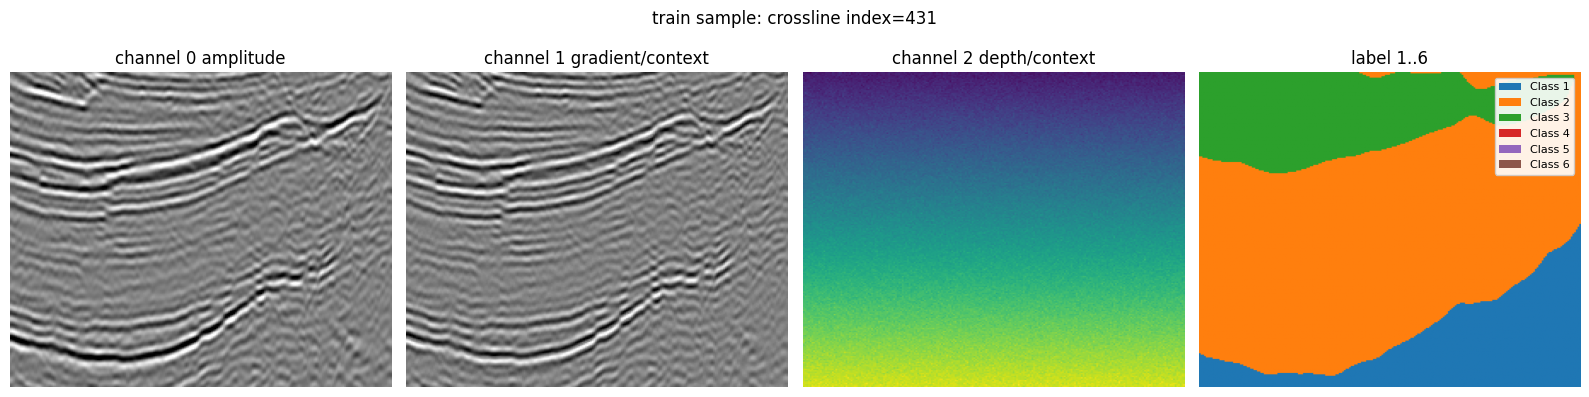

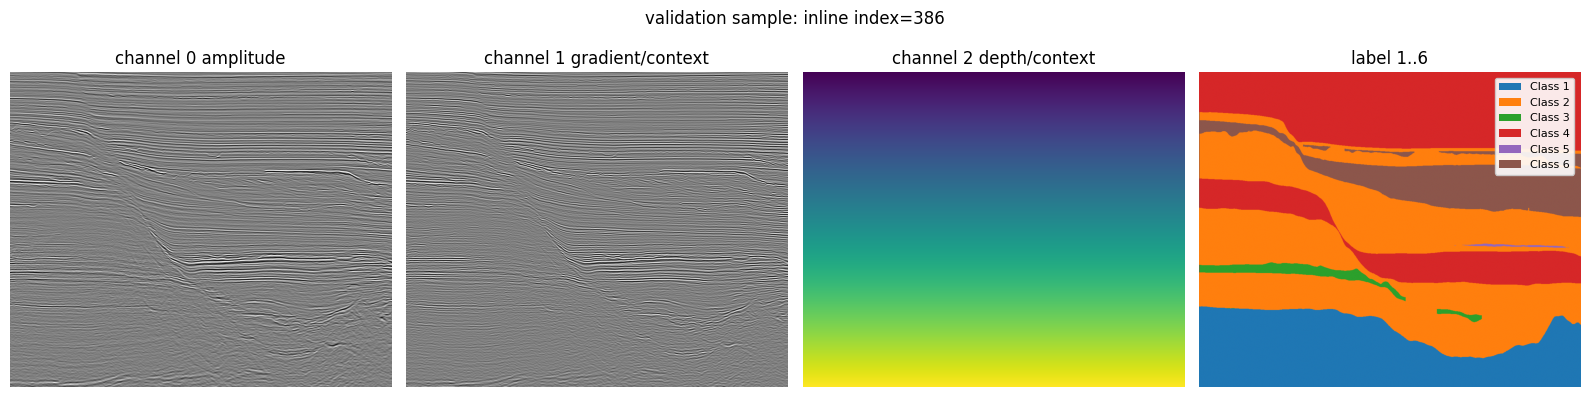

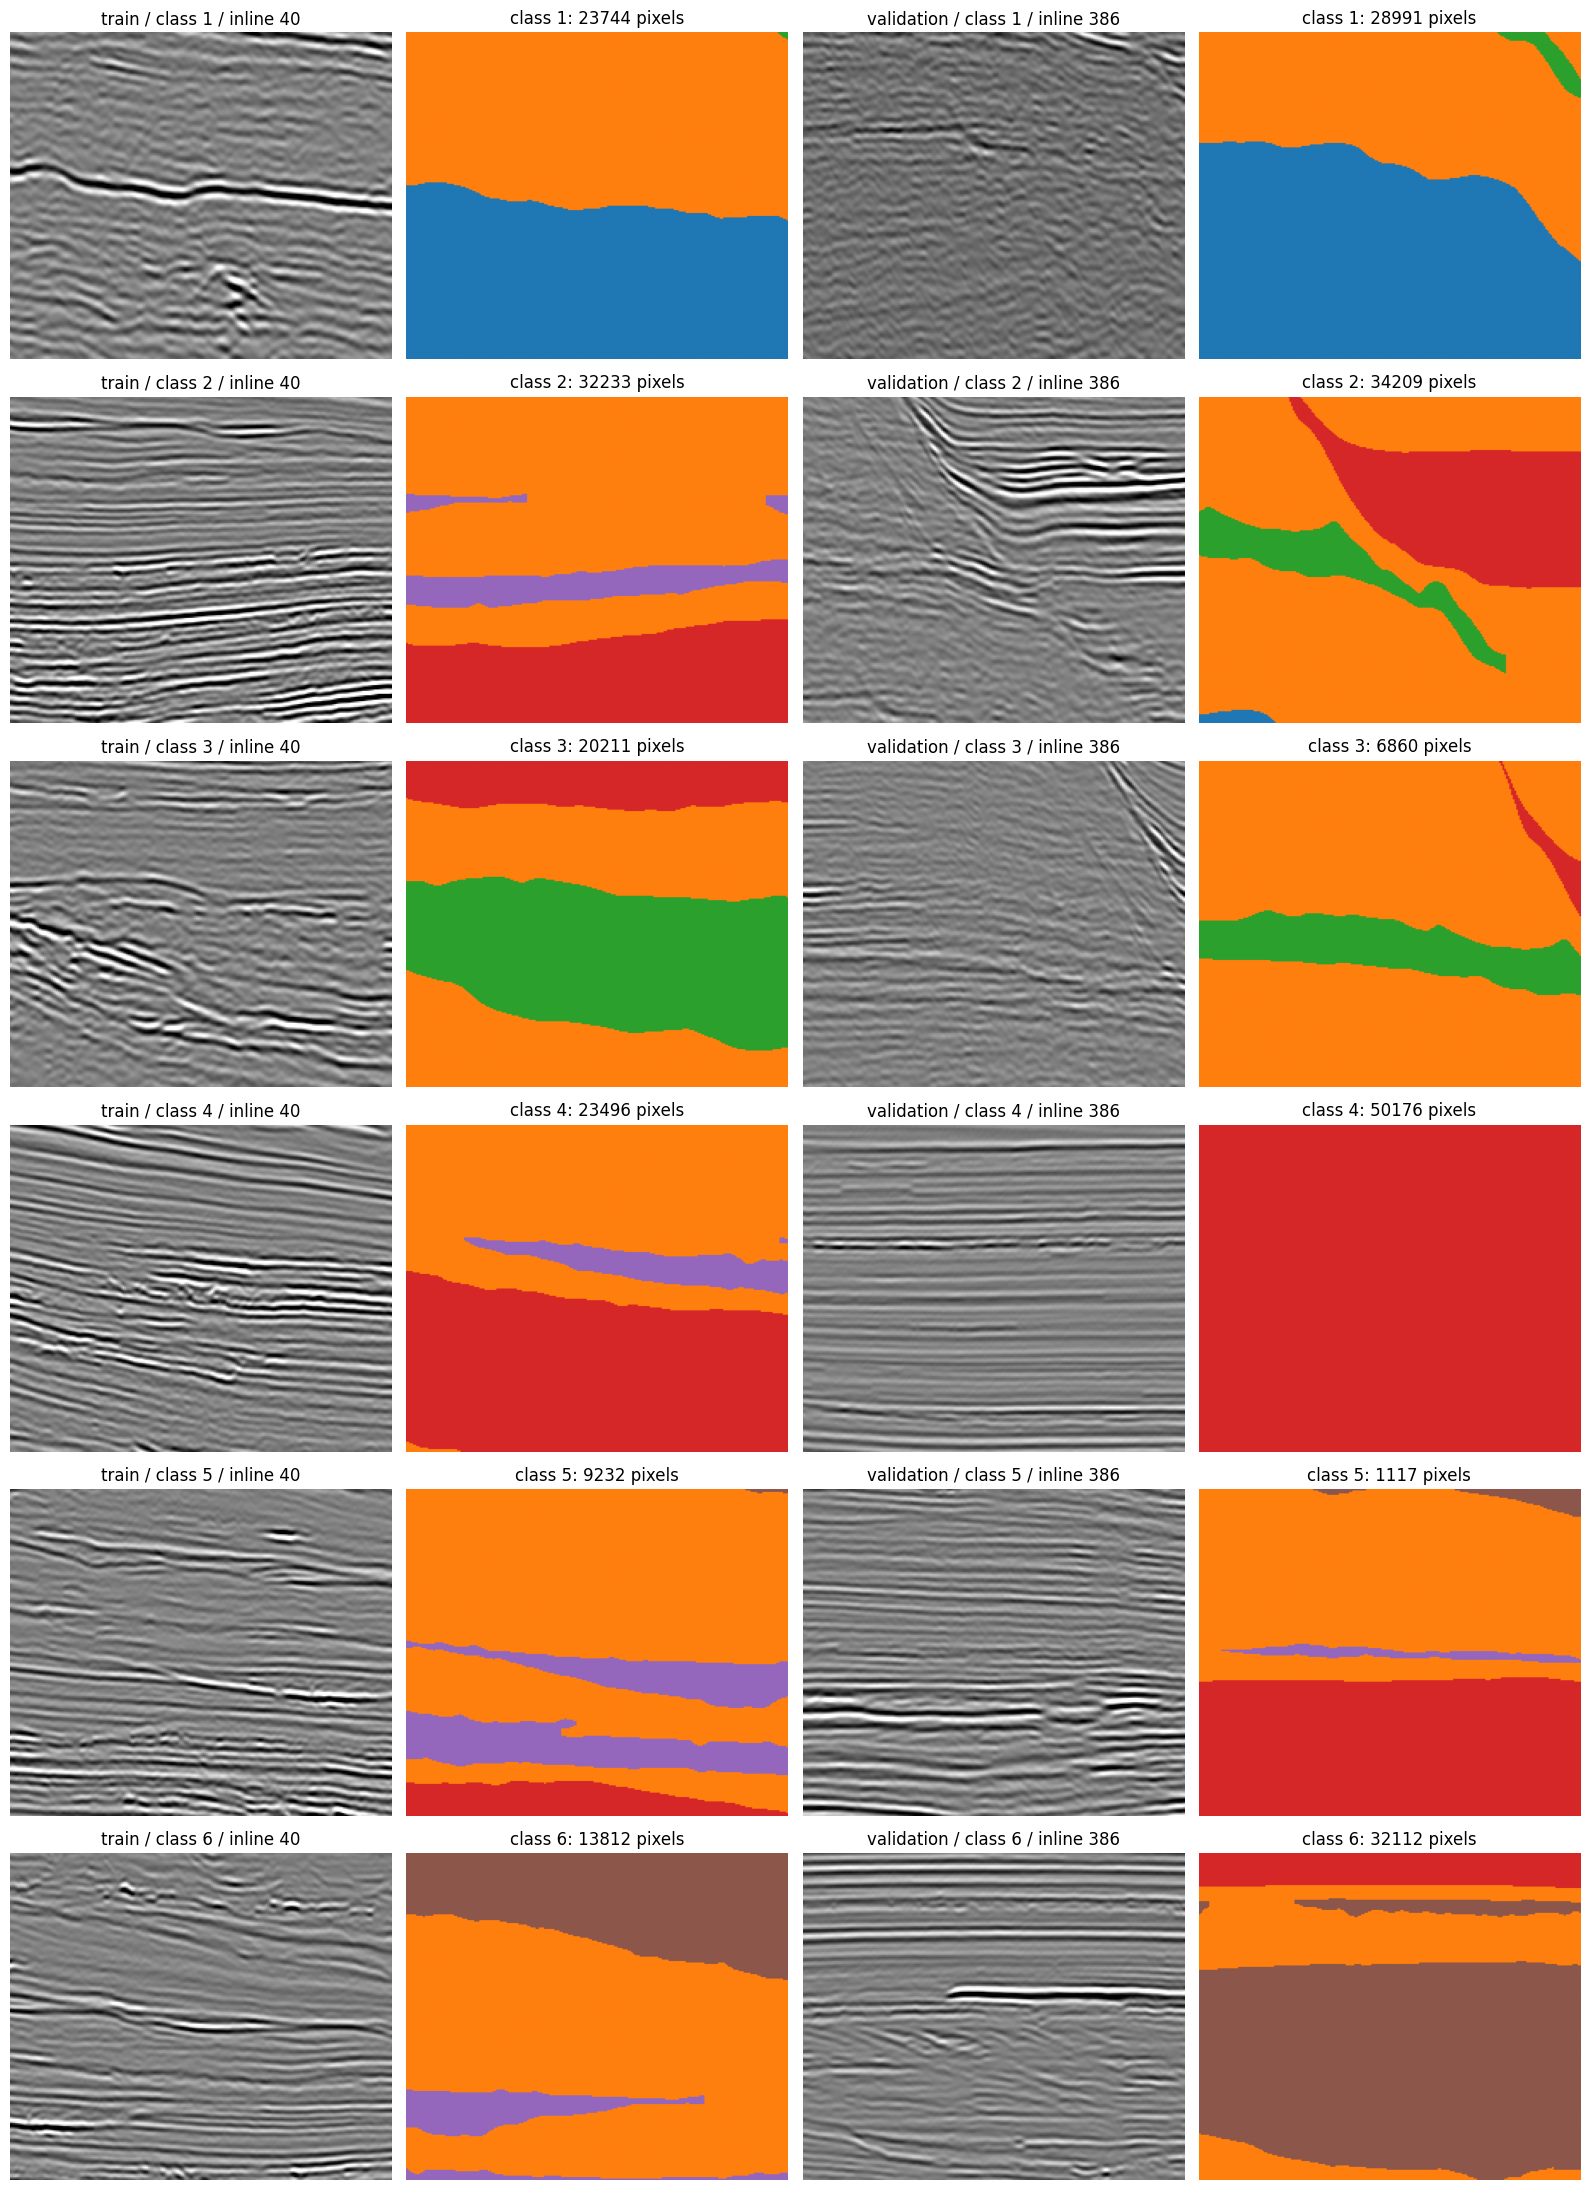

In [ ]:
# Dataset QC: check that the model features and labels show the same section.
from src.visualization import FACIES_CMAP, FACIES_NORM, add_facies_legend, display_section
import matplotlib.pyplot as plt

def show_dataset_item(ds, idx, title):
    item = ds[idx]
    image = item['image'].numpy()
    mask = item['mask'].numpy() + 1
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(display_section(image[0]), cmap='gray', aspect='auto')
    axes[0].set_title('channel 0 amplitude')
    axes[1].imshow(display_section(image[1]), cmap='gray', aspect='auto')
    axes[1].set_title('channel 1 gradient/context')
    axes[2].imshow(display_section(image[2]), cmap='viridis', aspect='auto')
    axes[2].set_title('channel 2 depth/context')
    axes[3].imshow(display_section(mask), cmap=FACIES_CMAP, norm=FACIES_NORM, aspect='auto')
    axes[3].set_title('label 1..6')
    add_facies_legend(axes[3])
    fig.suptitle(f"{title}: {item['orientation']} index={item['index']}")
    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

show_dataset_item(train_ds, 0, 'train sample')
show_dataset_item(val_ds, 0, 'validation sample')

# Show one real example from the training and validation regions for each class.
# These selected examples do not contribute to the validation score.
fig, axes = plt.subplots(6, 4, figsize=(16, 22))
for row, class_label in enumerate(range(1, 7)):
    for side, (name, ds) in enumerate((('train', train_ds), ('validation', val_ds))):
        item = ds.example_for_class(class_label)
        ax_image, ax_mask = axes[row, side * 2:side * 2 + 2]
        if item is None:
            ax_image.text(0.5, 0.5, f'No suitable {name} patch for class {class_label}', ha='center', va='center')
            ax_image.set_title(f'{name} / class {class_label}')
            ax_mask.axis('off')
            continue
        image = item['image'][0].numpy()
        mask = item['mask'].numpy() + 1
        count = int((mask == class_label).sum())
        ax_image.imshow(display_section(image), cmap='gray', aspect='auto')
        ax_image.set_title(f'{name} / class {class_label} / {item["orientation"]} {item["index"]}')
        ax_mask.imshow(display_section(mask), cmap=FACIES_CMAP, norm=FACIES_NORM, aspect='auto')
        ax_mask.set_title(f'class {class_label}: {count} pixels')
        for ax in (ax_image, ax_mask):
            ax.axis('off')
plt.tight_layout()
plt.show()


In [ ]:
from src.models import build_model

model = build_model(cfg)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)
with torch.no_grad():
    smoke = batch0['image'].unsqueeze(0).to(device)
    logits = model(smoke)
print('logits', logits.shape)
assert logits.shape[1] == 6

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

logits torch.Size([1, 6, 224, 224])


In [ ]:
# Optional sanity test: can the model overfit a single example?
# Set RUN_TINY_OVERFIT_TEST=True to train a separate debug model on one sample for 30 steps.
# If loss does not clearly decrease, check feature-label alignment and the model or loss.
RUN_TINY_OVERFIT_TEST = False
if RUN_TINY_OVERFIT_TEST:
    from src.losses import build_loss
    debug_model = build_model(cfg).to(device)
    debug_model.train()
    debug_opt = torch.optim.AdamW(debug_model.parameters(), lr=cfg['training']['decoder_lr'])
    debug_loss_fn = build_loss('ce_dice', None, cfg['model']['num_classes'])
    x = batch0['image'].unsqueeze(0).to(device)
    y = batch0['mask'].unsqueeze(0).to(device)
    losses = []
    for step in range(30):
        debug_opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type='cuda', dtype=torch.bfloat16, enabled=torch.cuda.is_available() and torch.cuda.is_bf16_supported()):
            loss = debug_loss_fn(debug_model(x), y)
        loss.backward()
        debug_opt.step()
        losses.append(float(loss.detach().cpu()))
    print('tiny overfit first/last loss:', losses[0], losses[-1])
    plt.plot(losses)
    plt.title('Tiny overfit loss')
    plt.xlabel('step')
    plt.ylabel('loss')
    plt.show()
    del debug_model
    torch.cuda.empty_cache()

Output directory: /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/dinov2_small_fapm


train 0:   0%|          | 0/32 [00:00<?, ?it/s]

validate full inline:   0%|          | 0/8 [00:00<?, ?it/s]

train 1:   0%|          | 0/32 [00:00<?, ?it/s]

validate full inline:   0%|          | 0/8 [00:00<?, ?it/s]

...

train 13:   0%|          | 0/32 [00:00<?, ?it/s]

validate full inline:   0%|          | 0/8 [00:00<?, ?it/s]

train 14:   0%|          | 0/32 [00:00<?, ?it/s]

validate full inline:   0%|          | 0/8 [00:00<?, ?it/s]

Saved training files:
  /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/dinov2_small_fapm/split_inline.json 1392 bytes
  /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/dinov2_small_fapm/normalization_train_only.json 746 bytes
  /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/dinov2_small_fapm/logs/run_status.json 80 bytes
  /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/dinov2_small_fapm/logs/experiment_results.csv 8686 bytes
  /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/dinov2_small_fapm/logs/batch_losses.csv 31682 bytes
  /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/dinov2_small_fapm/logs/last_validation_metrics.json 4494 bytes
  /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/dinov2_small_fapm/logs/best_validation_metrics.json 4493 bytes
  /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/dinov2_small_fapm/checkpoints/best_model.pth 243675260 bytes
 

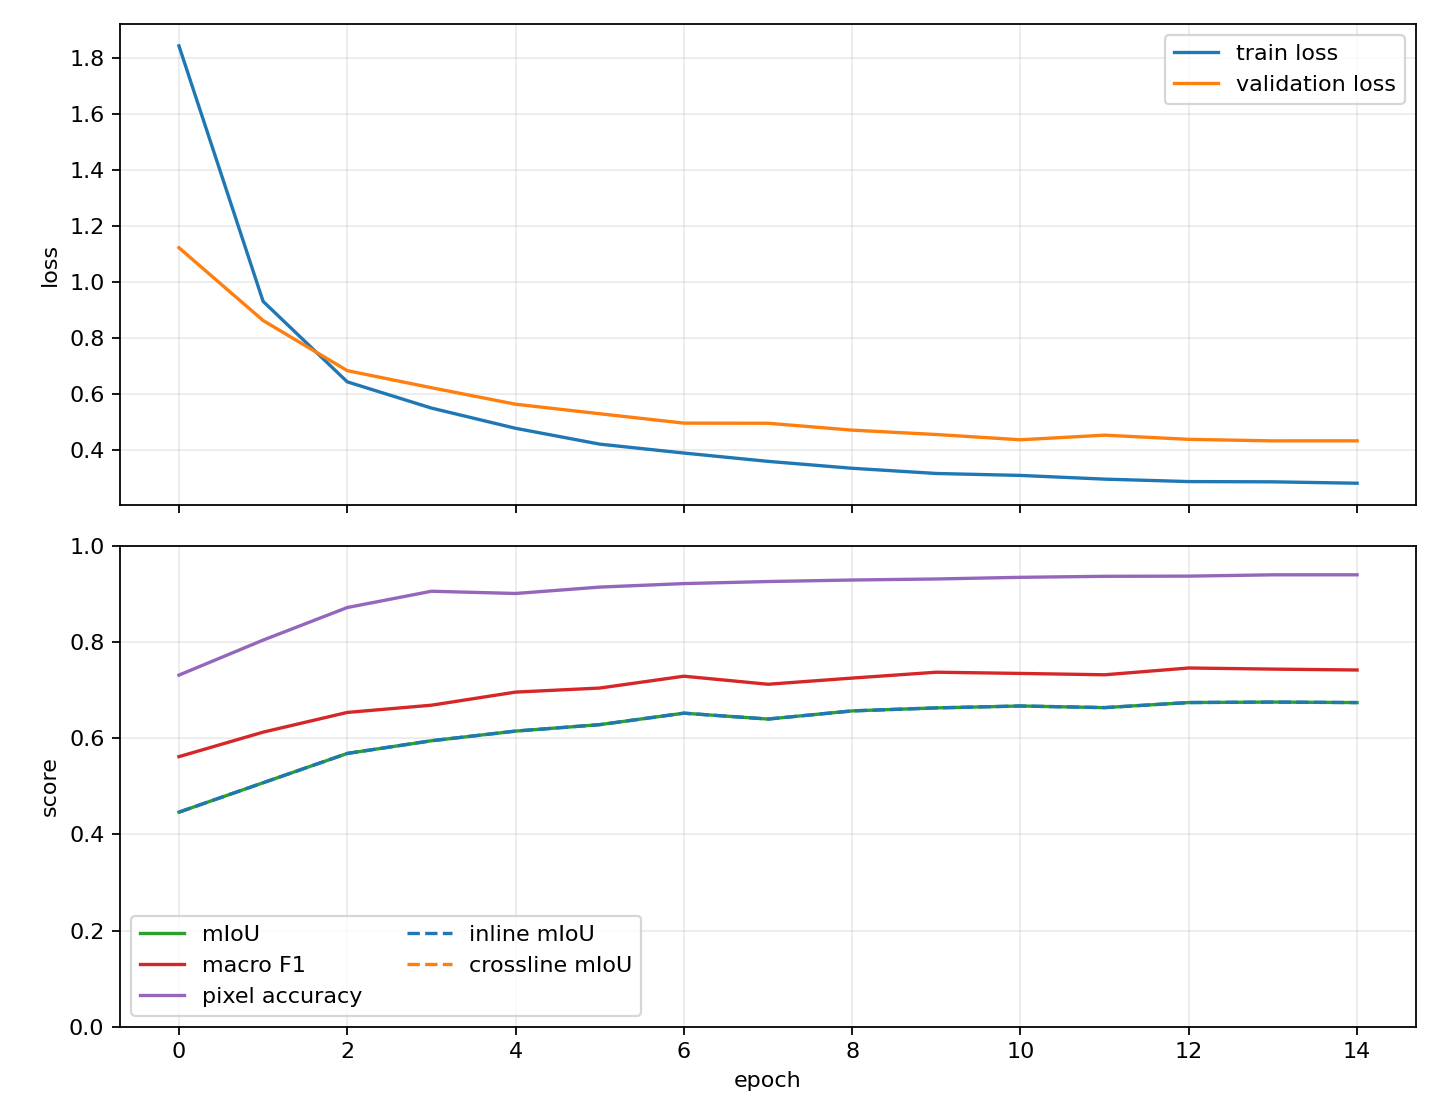

,epoch,train_loss,val_loss,val_nll,miou,class_iou,class_f1,macro_f1,weighted_f1,pixel_accuracy,mean_class_accuracy,frequency_weighted_iou,inline_miou,crossline_miou,inline_macro_f1,crossline_macro_f1,lr,lr_groups,epoch_time_sec,peak_gpu_gb
5,5,0.422313,0.530792,0.223400,0.627963,"[0.9186643829007789, 0.8085143936318548, 0.308...","[0.9576082102612173, 0.8941199433953058, 0.471...",0.704064,0.915236,0.913887,0.754279,0.849001,0.627963,NaN,0.704064,NaN,0.000073,"[7.3109477608084e-05, 7.310947760808401e-06]",33.896588,46.752022
6,6,0.390470,0.497344,0.209329,0.651807,"[0.9208507416499591, 0.823470997582271, 0.4149...","[0.9587946857952878, 0.9031906717179558, 0.586...",0.728654,0.922861,0.921177,0.785076,0.860713,0.651807,NaN,0.728654,NaN,0.000063,"[6.306974436292494e-05, 6.306974436292493e-06]",33.040040,46.752022
7,7,0.360790,0.496878,0.188765,0.639585,"[0.9306775614957116, 0.8357745350633224, 0.358...","[0.9640942434475782, 0.9105415933166253, 0.527...",0.711933,0.925330,0.925447,0.716233,0.865879,0.639585,NaN,0.711933,NaN,0.000053,"[5.25e-05, 5.2500000000000006e-06]",32.725643,46.752022
8,8,0.336077,0.472280,0.184364,0.656558,"[0.9321670291771991, 0.8413671200896036, 0.444...","[0.9648928018134709, 0.913850487401623, 0.6150...",0.724764,0.929552,0.928605,0.740625,0.871936,0.656558,NaN,0.724764,NaN,0.000042,"[4.1930255637075066e-05, 4.193025563707507e-06]",31.208735,46.752022
9,9,0.317517,0.456656,0.176237,0.662790,"[0.9308585251682728, 0.8457675552383283, 0.413...","[0.9641913304726966, 0.9164399415712142, 0.585...",0.736951,0.931589,0.930768,0.762217,0.875746,0.662790,NaN,0.736951,NaN,0.000032,"[3.189052239191599e-05, 3.189052239191599e-06]",34.049287,46.752022
10,10,0.310551,0.437855,0.168872,0.666723,"[0.9336922410571464, 0.8498604427844693, 0.441...","[0.965709249106464, 0.9188373599742822, 0.6125...",0.734434,0.935228,0.934203,0.758644,0.881910,0.666723,NaN,0.734434,NaN,0.000023,"[2.288423441171016e-05, 2.288423441171016e-06]",32.047052,46.752022
11,11,0.297323,0.454334,0.168975,0.663373,"[0.9301476246239466, 0.8583644464103318, 0.400...","[0.9638098275567587, 0.9237848346360396, 0.572...",0.731618,0.936268,0.936300,0.735739,0.883941,0.663373,NaN,0.731618,NaN,0.000015,"[1.5363004582768588e-05, 1.5363004582768586e-06]",32.599435,46.752022
12,12,0.288587,0.439382,0.168358,0.673903,"[0.9320733065683318, 0.8580351049320686, 0.431...","[0.9648425899779566, 0.9235940727432479, 0.602...",0.745747,0.937147,0.936683,0.762477,0.885140,0.673903,NaN,0.745747,NaN,0.000010,"[9.703978774635095e-06, 9.703978774635096e-07]",31.686285,46.752022
13,13,0.287652,0.433924,0.161939,0.674868,"[0.9342690537916705, 0.8624093152639034, 0.441...","[0.9660176819354683, 0.9261222097589219, 0.612...",0.743410,0.939464,0.939402,0.750524,0.889224,0.674868,NaN,0.743410,NaN,0.000006,"[6.190924171363378e-06, 6.190924171363378e-07]",32.881896,46.752022
14,14,0.282718,0.434082,0.160506,0.673831,"[0.9334823586273562, 0.8635978949282909, 0.435...","[0.9655969752835671, 0.9268071157179764, 0.607...",0.741569,0.939583,0.939439,0.749960,0.889426,0.673831,NaN,0.741569,NaN,0.000005,"[5e-06, 5.000000000000001e-07]",32.951058,46.752022


,epoch,step,batch_loss,running_loss,lr
460,14,12,0.289424,0.284814,0.000005
461,14,13,0.280830,0.284530,0.000005
462,14,14,0.286090,0.284634,0.000005
463,14,15,0.272493,0.283875,0.000005
464,14,16,0.272030,0.283178,0.000005
465,14,17,0.303814,0.284325,0.000005
466,14,18,0.271112,0.283629,0.000005
467,14,19,0.272800,0.283088,0.000005
468,14,20,0.300938,0.283938,0.000005
469,14,21,0.277386,0.283640,0.000005


{'epoch': 14,
 'train_loss': 0.2827176498249173,
 'val_loss': 0.43408234417438507,
 'val_nll': 0.16050618866127087,
 'miou': 0.6738307514435751,
 'class_iou': '[0.9334823586273562, 0.8635978949282909, 0.4357659415506699, 0.939386547347166, 0.03743618831537152, 0.8333155778925962]',
 'class_f1': '[0.9655969752835671, 0.9268071157179764, 0.6070152925901413, 0.968746069350772, 0.07217058501913613, 0.9090803437676518]',
 'macro_f1': 0.7415693969548741,
 'weighted_f1': 0.9395827801766357,
 'pixel_accuracy': 0.9394392913618036,
 'mean_class_accuracy': 0.7499599234953563,
 'frequency_weighted_iou': 0.8894258232147554,
 'inline_miou': 0.6738307514435751,
 'crossline_miou': None,
 'inline_macro_f1': 0.7415693969548741,
 'crossline_macro_f1': None,
 'lr': 5e-06,
 'lr_groups': '[5e-06, 5.000000000000001e-07]',
 'epoch_time_sec': 32.95105838775635,
 'peak_gpu_gb': 46.75202226638794}

In [ ]:
from src.trainer import Trainer
from src.visualization import save_training_curves
from IPython.display import Image, display
import pandas as pd

trainer = Trainer(model, cfg, train_ds, val_ds, normalization, split, device=device)
print('Output directory:', resolve_path(cfg, cfg['outputs']['dir']).resolve())
history = trainer.fit()
required_after_training = [resolve_path(cfg, cfg['split']['path']),
                           resolve_path(cfg, cfg['normalization']['path']),
                           trainer.status_path, trainer.log_path, trainer.batch_log_path,
                           trainer.metrics_json, trainer.best_metrics_json, trainer.best_path, trainer.last_path]
missing_after_training = [str(path) for path in required_after_training if not path.exists()]
if missing_after_training:
    raise FileNotFoundError(f'Training finished but output files are missing: {missing_after_training}')
print('Saved training files:')
for path in required_after_training:
    print(' ', path.resolve(), path.stat().st_size, 'bytes')
curve_path = resolve_path(cfg, cfg['outputs']['figures']) / 'training_curves.png'
save_training_curves(history, curve_path)
display(Image(filename=str(curve_path)))
epoch_log = pd.read_csv(resolve_path(cfg, cfg['outputs']['logs']) / 'experiment_results.csv')
batch_log = pd.read_csv(resolve_path(cfg, cfg['outputs']['logs']) / 'batch_losses.csv')
display(epoch_log.tail(10))
display(batch_log.tail(20))
if trainer.tracker.enabled and getattr(trainer.tracker, 'run_id', None):
    import mlflow
    with mlflow.start_run(run_id=trainer.tracker.run_id):
        mlflow.log_artifacts(str(resolve_path(cfg, cfg['outputs']['logs'])), artifact_path='logs')
        mlflow.log_artifacts(str(resolve_path(cfg, cfg['outputs']['figures'])), artifact_path='figures')
    print('MLflow run logged to:', cfg['tracking']['mlflow']['tracking_uri'], 'run_id=', trainer.tracker.run_id)
history[-1] if history else None

In [ ]:
from src.checkpoint import load_checkpoint

best_path = resolve_path(cfg, cfg['outputs']['checkpoints']) / 'best_model.pth'
ckpt = load_checkpoint(best_path, model, map_location=device)
normalization = ckpt['normalization']
split = ckpt['split']
verify_comparison_split(split)
if [idx for _, idx in val_ds.indices] != validation_indices:
    raise ValueError('Validation indices changed after loading the checkpoint.')
print('loaded best mIoU', ckpt['best_miou'])

loaded best mIoU 0.6748681485695464


validation mIoU: 0.6748681485695464
validation pixel NLL: 0.16193900177896814
validation macro/weighted F1: 0.74341014219135 0.9394640472508908
validation pixel accuracy: 0.9394017925693918
orientation mIoU: {'inline': 0.6748681485695464}
full validation inline indices: [386, 396, 407, 417, 428, 449, 460, 471]
class IoU: [0.9342690537916705, 0.8624093152639034, 0.4414801200407794, 0.9411425694739016, 0.04170871173898419, 0.8281991211080395]
actual validation pixels / classes 1..6: [1214087, 2563232, 97367, 1835472, 2616, 580762]
predicted pixels / classes 1..6: [1258493, 2507656, 103411, 1839206, 3578, 581192]
class F1: [0.9660176819354683, 0.9261222097589219, 0.6125372301746208, 0.9696789759538114, 0.08007749434937037, 0.9060272609759078]
class NLL: [0.03536184964607063, 0.23289214935978533, 0.901657161546554, 0.0814648673834112, 2.5382716543288955, 0.23300714854416185]


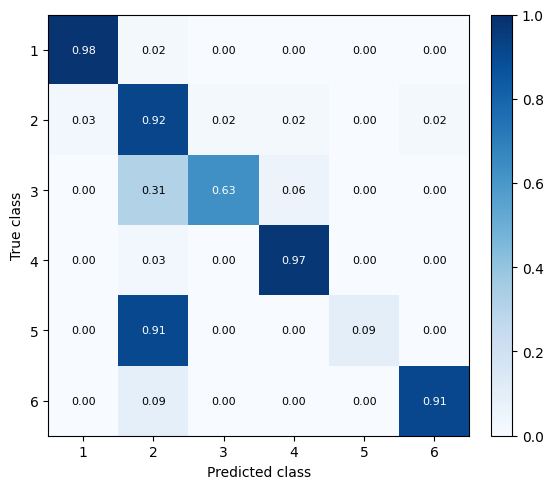

saved confusion matrix: /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/dinov2_small_fapm/figures/validation_confusion_matrix.png


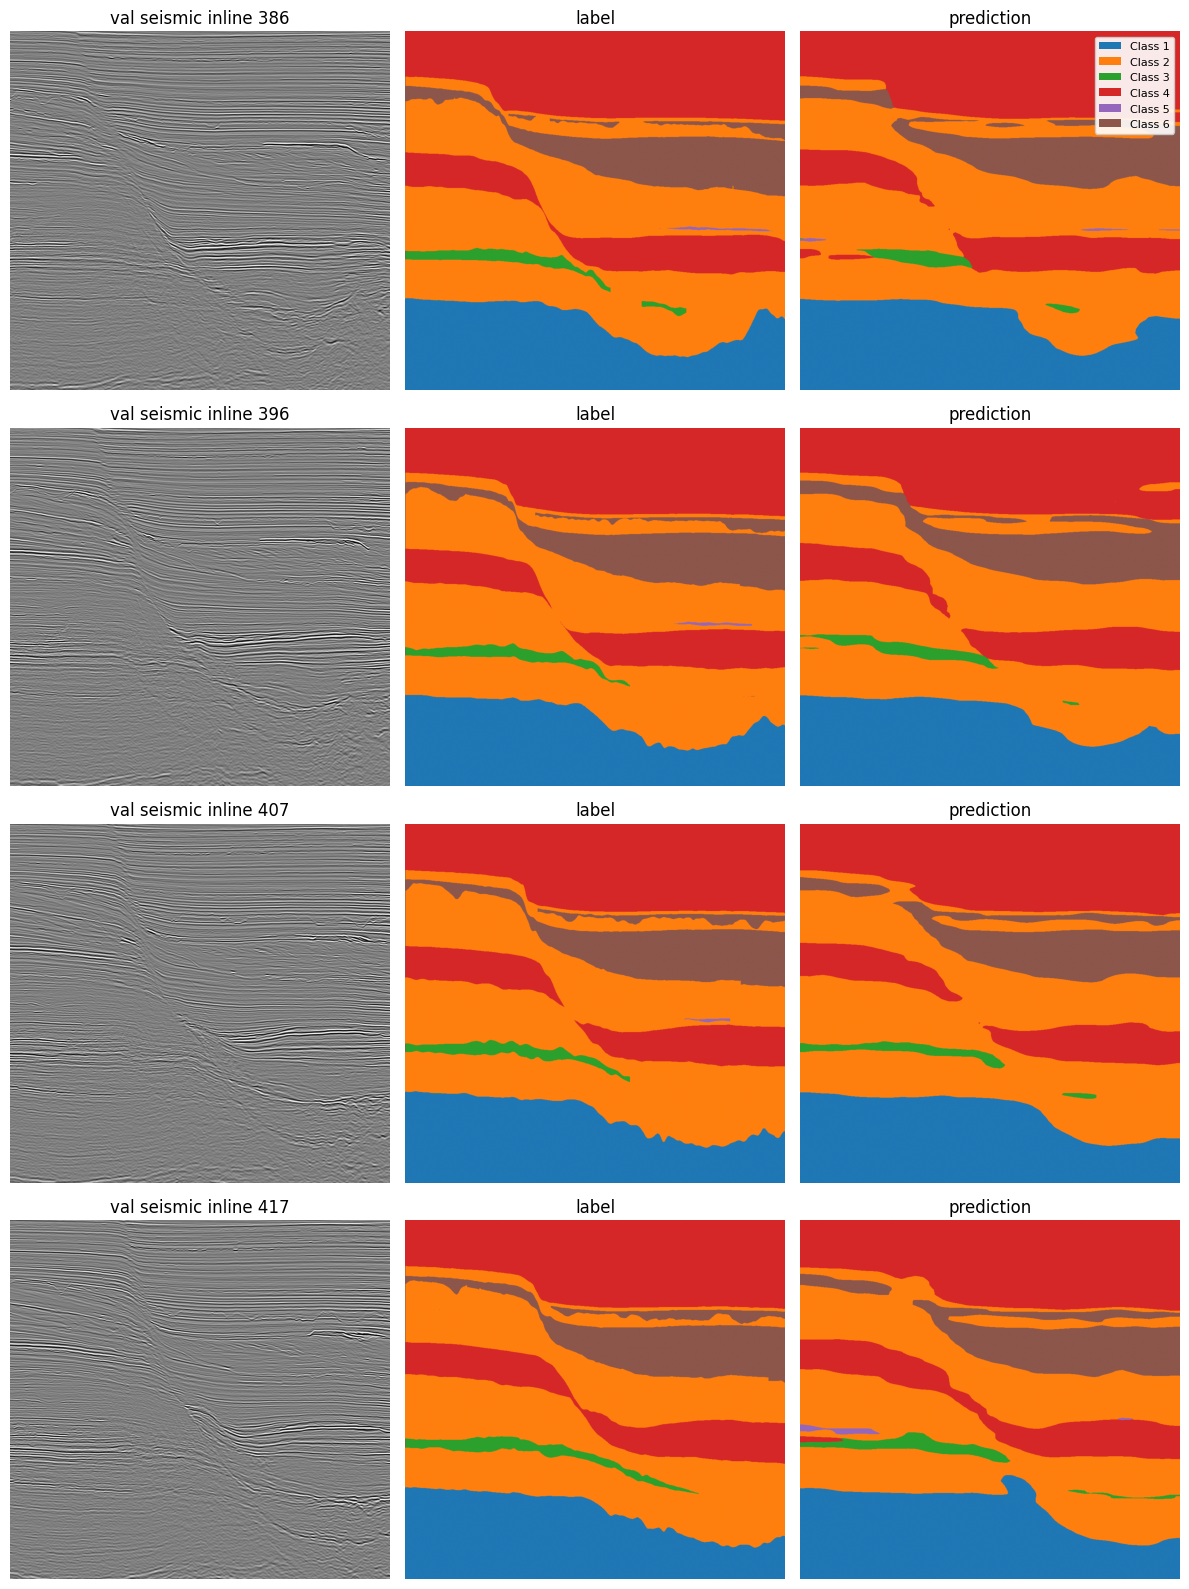

saved validation QC: /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/dinov2_small_fapm/figures/validation_prediction_qc.png


In [ ]:
# Validation QC: confusion matrix and predictions on several real validation sections.
import json
import matplotlib.pyplot as plt
from src.visualization import FACIES_CMAP, FACIES_NORM, add_facies_legend, display_section, plot_confusion_matrix
from src.inference import predict_section
from src.features import make_triplet
from IPython.display import Image, display

metrics_path = resolve_path(cfg, cfg['outputs']['logs']) / 'best_validation_metrics.json'
metrics = json.load(open(metrics_path, 'r'))
print('validation mIoU:', metrics['miou'])
print('validation pixel NLL:', metrics.get('val_nll'))
print('validation macro/weighted F1:', metrics['macro_f1'], metrics['weighted_f1'])
print('validation pixel accuracy:', metrics['pixel_accuracy'])
print('orientation mIoU:', {k: v['miou'] for k, v in metrics.get('orientation_metrics', {}).items()})
print('full validation inline indices:', metrics.get('validation_inlines'))
print('class IoU:', metrics['class_iou'])
print('actual validation pixels / classes 1..6:', metrics.get('class_support'))
print('predicted pixels / classes 1..6:', metrics.get('class_predicted'))
print('class F1:', metrics['class_f1'])
print('class NLL:', metrics.get('class_nll'))
cm_path = resolve_path(cfg, cfg['outputs']['figures']) / 'validation_confusion_matrix.png'
fig = plot_confusion_matrix(np.array(metrics['confusion_matrix']), cm_path)
plt.show()
print('saved confusion matrix:', cm_path)

model.eval()
n_show = min(4, len(val_ds))
fig, axes = plt.subplots(n_show, 3, figsize=(12, 4 * n_show))
axes = np.atleast_2d(axes)
with torch.no_grad():
    for row in range(n_show):
        item = val_ds[row]
        if getattr(val_ds, 'full_inline', False):
            triplet = make_triplet(train_seismic, 'inline', int(item['index']), bounds=tuple(split['val']))
            probs = predict_section(model, triplet, normalization, device, cfg)
            pred = probs.argmax(axis=0) + 1
        else:
            image = item['image'].unsqueeze(0).to(device)
            logits = model(image)
            pred = logits.argmax(dim=1).squeeze(0).cpu().numpy() + 1
        label = item['mask'].numpy() + 1
        seismic = item['image'][0].numpy()
        axes[row, 0].imshow(display_section(seismic), cmap='gray', aspect='auto')
        axes[row, 0].set_title(f"val seismic {item['orientation']} {item['index']}")
        axes[row, 1].imshow(display_section(label), cmap=FACIES_CMAP, norm=FACIES_NORM, aspect='auto')
        axes[row, 1].set_title('label')
        axes[row, 2].imshow(display_section(pred), cmap=FACIES_CMAP, norm=FACIES_NORM, aspect='auto')
        axes[row, 2].set_title('prediction')
        if row == 0:
            add_facies_legend(axes[row, 2])
        for col in range(3):
            axes[row, col].axis('off')
plt.tight_layout()
val_preview_path = resolve_path(cfg, cfg['outputs']['figures']) / 'validation_prediction_qc.png'
fig.savefig(val_preview_path, dpi=160)
plt.show()
print('saved validation QC:', val_preview_path)


In [ ]:
# Independent labeled test: run once after selecting the best validation checkpoint.
from src.dataset import FullInlineValidationDataset
from src.evaluation import evaluate_labeled_inlines
import json

if 'test' not in split:
    raise RuntimeError('Checkpoint has no labeled test split; train with the updated train/val/test config.')
if ckpt['config']['model']['backbone'] != cfg['model']['backbone']:
    raise RuntimeError('Best checkpoint backbone does not match the current config.')
test_ds = FullInlineValidationDataset(
    train_seismic, train_labels, split, normalization,
    feature_mode=cfg['feature_engineering']['mode'],
    subset='test', max_sections=None,
    diagnostic_patch_size=cfg['dataset']['patch_size'],
)
print('labeled test ranges:', split['test_ranges'], 'complete inlines:', len(test_ds))
test_metrics = evaluate_labeled_inlines(model, test_ds, normalization, device, cfg)
test_metrics['checkpoint_epoch'] = int(ckpt['epoch'])
test_metrics['best_validation_miou'] = float(ckpt['best_miou'])
test_metrics_path = resolve_path(cfg, cfg['outputs']['logs']) / 'labeled_test_metrics.json'
with open(test_metrics_path, 'w', encoding='utf-8') as f:
    json.dump(test_metrics, f, indent=2)
print('labeled test mIoU:', test_metrics['miou'])
print('labeled test class IoU:', test_metrics['class_iou'])
print('labeled test class support:', test_metrics['class_support'])
print('missing test classes:', test_metrics['missing_test_classes'])
print('labeled test pixel NLL:', test_metrics['test_nll'])
print('saved:', test_metrics_path.resolve())

# Fixed first test inline for a comparable visual across all three models.
import matplotlib.pyplot as plt
import numpy as np
from src.features import make_triplet
from src.inference import predict_section
from src.visualization import FACIES_CMAP, FACIES_NORM, add_facies_legend, display_section, plot_confusion_matrix

test_cm_path = resolve_path(cfg, cfg['outputs']['figures']) / 'labeled_test_confusion_matrix.png'
fig = plot_confusion_matrix(np.asarray(test_metrics['confusion_matrix']), test_cm_path)
plt.close(fig)
test_item = test_ds[0]
test_idx = int(test_item['index'])
test_triplet = make_triplet(train_seismic, 'inline', test_idx, bounds=range_for_index(split, 'test', test_idx))
test_pred = predict_section(model, test_triplet, normalization, device, cfg).argmax(axis=0) + 1
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(display_section(test_item['image'][0].numpy()), cmap='gray', aspect='auto')
axes[0].set_title(f'test seismic inline {test_idx}')
axes[1].imshow(display_section(test_item['mask'].numpy() + 1), cmap=FACIES_CMAP, norm=FACIES_NORM, aspect='auto')
axes[1].set_title('label')
axes[2].imshow(display_section(test_pred), cmap=FACIES_CMAP, norm=FACIES_NORM, aspect='auto')
axes[2].set_title('prediction')
add_facies_legend(axes[2])
for ax in axes:
    ax.axis('off')
fig.tight_layout()
test_preview_path = resolve_path(cfg, cfg['outputs']['figures']) / 'labeled_test_prediction_qc.png'
fig.savefig(test_preview_path, dpi=160)
plt.close(fig)
print('saved test figures:', test_cm_path.resolve(), test_preview_path.resolve())


labeled test ranges: [[0, 31], [107, 138], [558, 590]] complete inlines: 94


test labeled inlines:   0%|          | 0/94 [00:00<?, ?it/s]

labeled test mIoU: 0.8325468148794153
labeled test class IoU: [0.9736081105083463, 0.8741584132592637, 0.8024566235901107, 0.9247414195935385, 0.5779968637597761, 0.842319458565457]
labeled test class support: [11834429, 31313072, 4527496, 19669382, 1281905, 5322764]
missing test classes: []
labeled test pixel NLL: 0.14979426661863043
saved: /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/dinov2_small_fapm/logs/labeled_test_metrics.json
saved test figures: /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/dinov2_small_fapm/figures/labeled_test_confusion_matrix.png /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/dinov2_small_fapm/figures/labeled_test_prediction_qc.png


In [ ]:
# Portable manifest for the downloaded experiment folder.
import json as _json
from pathlib import Path as _Path
output_root = resolve_path(cfg, cfg['outputs']['dir']).resolve()
run_config_path = resolve_path(cfg, cfg['outputs']['logs']) / 'run_config.json'
with open(run_config_path, 'w', encoding='utf-8') as f:
    _json.dump(cfg, f, indent=2)
artifact_paths = required_after_training + [curve_path, cm_path, val_preview_path,
                           test_metrics_path, test_cm_path, test_preview_path, run_config_path]
files, missing_artifacts = {}, []
for path in artifact_paths:
    resolved = _Path(path).resolve()
    relative = resolved.relative_to(output_root).as_posix()
    if not resolved.is_file() or resolved.stat().st_size == 0:
        missing_artifacts.append(relative)
    else:
        files[relative] = resolved.stat().st_size
manifest_path = resolve_path(cfg, cfg['outputs']['logs']) / 'artifact_manifest.json'
with open(manifest_path, 'w', encoding='utf-8') as f:
    _json.dump({'schema_version': 1, 'model': cfg['model']['name'],
                'backbone': cfg['model'].get('backbone'),
                'run_name': cfg['tracking']['mlflow']['run_name'],
                'parameters_total': sum(p.numel() for p in model.parameters()),
                'parameters_trainable_final': sum(p.numel() for p in model.parameters() if p.requires_grad),
                'split': split, 'files': files, 'missing': missing_artifacts}, f, indent=2)
print('Artifact manifest:', manifest_path.resolve())
if missing_artifacts:
    raise FileNotFoundError(f'Missing artifacts: {missing_artifacts}')


Artifact manifest: /content/drive/MyDrive/parihaka_dino_unet/outputs/comparison_v2/dinov2_small_fapm/logs/artifact_manifest.json


## Training and evaluation outputs

- `outputs/logs/experiment_results.csv`: loss and classification metrics by epoch.
- `outputs/logs/best_validation_metrics.json`: validation metrics for the selected checkpoint epoch.
- `outputs/checkpoints/best_model.pth`: model selected by validation mIoU.
- `outputs/logs/labeled_test_metrics.json`: one-time evaluation of the selected model on the labeled test region.
- `outputs/figures/`: training curves, confusion matrices, and validation examples.
